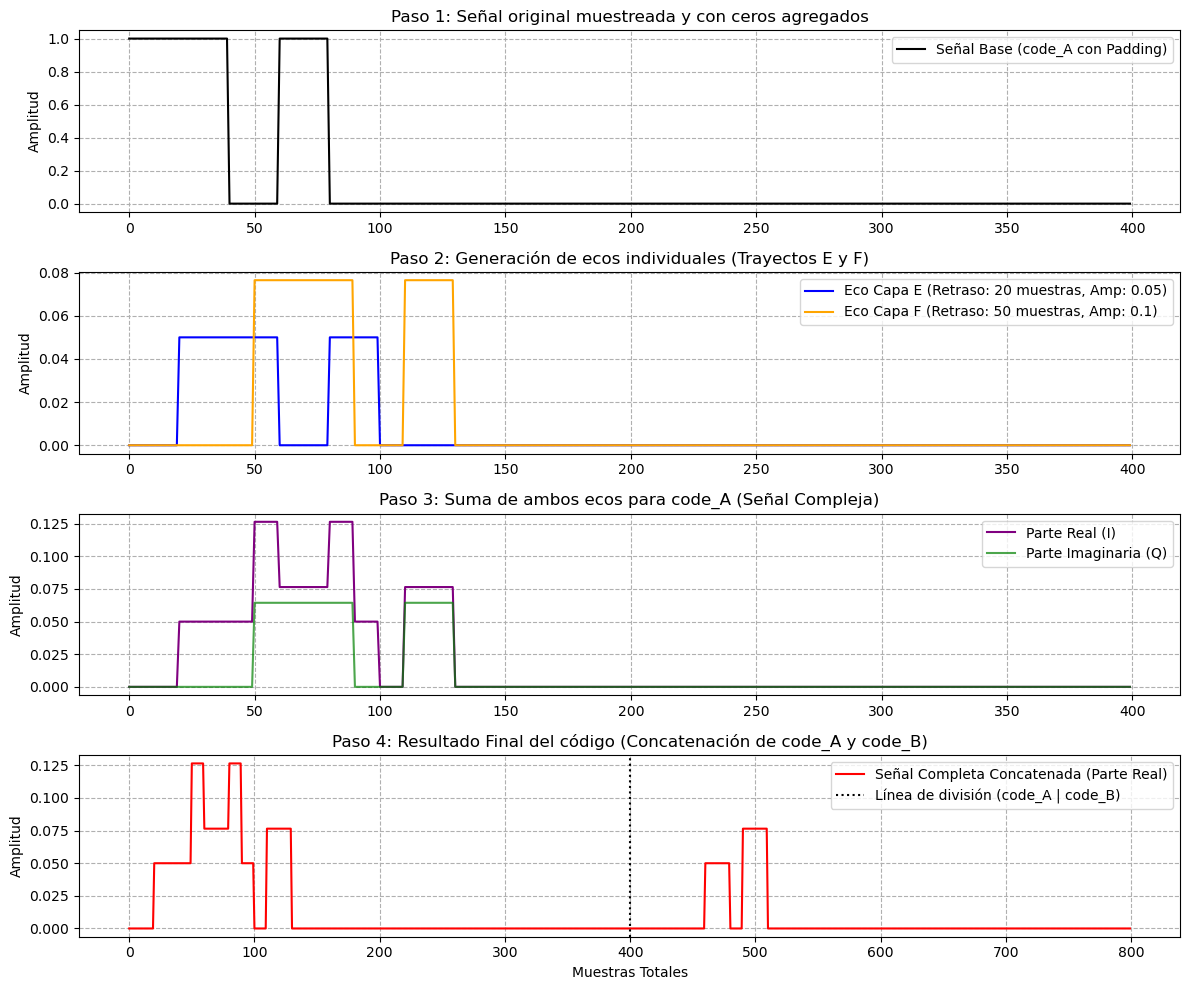

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Configuración de parámetros de simulación
spb = 20          # Muestras por bit (Samples per bit)
n_vec = 400       # Ampliado a 400 para albergar los bits y los retrasos sin recortar
dh_km = 5         # Resolución espacial (5 km por muestra)
h_E = 100         # Altura de la Capa E (100 km)
h_F = 250         # Altura de la Capa F (250 km)

# Señales de prueba (Asegúrate de que no tengan campos vacíos)
code_A = np.array([1, 1, 0, 1])
code_B = np.array([0, 0, 1, 0])

# --- CORRECCIÓN AQUÍ ---
# Calculamos dinámicamente cuántos ceros faltan para llegar a 'n_vec'
padding_A = n_vec - len(np.repeat(code_A, spb))
padding_B = n_vec - len(np.repeat(code_B, spb))

# 2. Recreación del proceso paso a paso para code_A
base_signal = np.pad(np.repeat(code_A, spb), (0, padding_A)).astype(complex)

# Retrasos calculados (en número de muestras)
delay_E = int(round(h_E / dh_km))  # 100 / 5 = 20 muestras
delay_F = int(round(h_F / dh_km))  # 250 / 5 = 50 muestras

# Eco Capa E: Retraso + Atenuación (0.05)
echo_E = np.roll(base_signal, delay_E) * 0.05

# Eco Capa F: Retraso + Atenuación (0.1) + Desfase (0.7 rad)
echo_F = np.roll(base_signal, delay_F) * 0.1 * np.exp(1j * 0.7)

# Señal combinada para code_A
signal_A_final = echo_E + echo_F

# 3. Tu línea original corregida dinámicamente para no fallar por tamaños fijados
resultado_original = np.concatenate([
    np.roll(np.pad(np.repeat(cd, spb), (0, n_vec - len(np.repeat(cd, spb)))).astype(complex), int(round(h_E / dh_km))) * 0.05 + 
    np.roll(np.pad(np.repeat(cd, spb), (0, n_vec - len(np.repeat(cd, spb)))).astype(complex), int(round(h_F / dh_km))) * 0.1 * np.exp(1j * 0.7) 
    for cd in (code_A, code_B)
]).tolist()

# Convertimos el resultado final de vuelta a numpy para graficarlo fácilmente
resultado_original_np = np.array(resultado_original)

# --- CONFIGURACIÓN DE GRÁFICAS ---
plt.figure(figsize=(12, 10))

# Gráfica 1: La señal base extendida (Antes de los ecos)
plt.subplot(4, 1, 1)
plt.plot(base_signal.real, label='Señal Base (code_A con Padding)', color='black', lw=1.5)
plt.title('Paso 1: Señal original muestreada y con ceros agregados')
plt.ylabel('Amplitud')
plt.grid(True, linestyle='--')
plt.legend()

# Gráfica 2: Los dos ecos por separado
plt.subplot(4, 1, 2)
plt.plot(echo_E.real, label=f'Eco Capa E (Retraso: {delay_E} muestras, Amp: 0.05)', color='blue')
plt.plot(echo_F.real, label=f'Eco Capa F (Retraso: {delay_F} muestras, Amp: 0.1)', color='orange')
plt.title('Paso 2: Generación de ecos individuales (Trayectos E y F)')
plt.ylabel('Amplitud')
plt.grid(True, linestyle='--')
plt.legend()

# Gráfica 3: Suma de ecos para code_A
plt.subplot(4, 1, 3)
plt.plot(signal_A_final.real, label='Parte Real (I)', color='purple')
plt.plot(signal_A_final.imag, label='Parte Imaginaria (Q)', color='green', alpha=0.7)
plt.title('Paso 3: Suma de ambos ecos para code_A (Señal Compleja)')
plt.ylabel('Amplitud')
plt.grid(True, linestyle='--')
plt.legend()

# Gráfica 4: Concatenación final (code_A + code_B)
plt.subplot(4, 1, 4)
plt.plot(resultado_original_np.real, color='red', label='Señal Completa Concatenada (Parte Real)')
plt.axvline(x=n_vec, color='black', linestyle=':', label='Línea de división (code_A | code_B)')
plt.title('Paso 4: Resultado Final del código (Concatenación de code_A y code_B)')
plt.xlabel('Muestras Totales')
plt.ylabel('Amplitud')
plt.grid(True, linestyle='--')
plt.legend()

plt.tight_layout()
plt.show()
